# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

#### Configuración del preprocesamiento

Se cargaron los 18 documentos de mediante sus identificadores originales. Para cada libro se conservó el texto de gutenberg.raw() y se generó una lista de tokens. La cantidad de caracteres se calculó sobre el texto original

La normalización que se hizo convierte el texto a minúsculas, unifica dos formas tipográficas del apóstrofo, sustituye el guion bajo por un espacio y aplica Unicode NFC. La expresión regular compilada \w+(?:'\w+)* toma secuencias de letras, dígitos y otros caracteres de palabra donde también conservó apóstrofos interiores. La puntuación restante actúa como separador. Se conservaron las tildes, números y encabezados de Gutenberg.

In [1]:
import re
import unicodedata
import nltk
from nltk.corpus import gutenberg

nltk.download("gutenberg", quiet=True)
identificadores = gutenberg.fileids()

if len(identificadores) != 18:
    raise ValueError("Se esperaban exactamente 18 documentos")


In [2]:
print(identificadores)

['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']


In [3]:
patron_token = re.compile(r"\w+(?:'\w+)*", flags=re.UNICODE)


In [4]:
textos_originales = {}
tokens_por_documento = {}


def normalizar_tokenizar(texto: str) -> list[str]:
    texto = texto.lower()
    texto = texto.replace("’", "'")
    texto = texto.replace("‘", "'")
    texto = texto.replace("_", " ")
    texto = unicodedata.normalize("NFC", texto)
    tokens = patron_token.findall(texto)
    return tokens


for doc_id in identificadores:
    texto = gutenberg.raw(doc_id)
    textos_originales[doc_id] = texto
    tokens_por_documento[doc_id] = normalizar_tokenizar(texto)

print("Numero de documentos:", len(identificadores))
total_caracteres = 0
total_tokens = 0
for doc_id in identificadores:
    cantidad_caracteres = len(textos_originales[doc_id])
    cantidad_tokens = len(tokens_por_documento[doc_id])
    total_caracteres += cantidad_caracteres
    total_tokens += cantidad_tokens
    print(doc_id, "| caracteres:", cantidad_caracteres, "| tokens:", cantidad_tokens)

print("Total de caracteres:", total_caracteres)
print("Total de tokens:", total_tokens)

ejemplo = "¡Árbol, árbol! O’Neill; co-operate 123."
print("Comprobacion:", normalizar_tokenizar(ejemplo))


Numero de documentos: 18
austen-emma.txt | caracteres: 887071 | tokens: 160999
austen-persuasion.txt | caracteres: 466292 | tokens: 83659
austen-sense.txt | caracteres: 673022 | tokens: 119965
bible-kjv.txt | caracteres: 4332554 | tokens: 852256
blake-poems.txt | caracteres: 38153 | tokens: 6839
bryant-stories.txt | caracteres: 249439 | tokens: 46321
burgess-busterbrown.txt | caracteres: 84663 | tokens: 15969
carroll-alice.txt | caracteres: 144395 | tokens: 26688
chesterton-ball.txt | caracteres: 457450 | tokens: 82245
chesterton-brown.txt | caracteres: 406629 | tokens: 72391
chesterton-thursday.txt | caracteres: 320525 | tokens: 58300
edgeworth-parents.txt | caracteres: 935158 | tokens: 167720
melville-moby_dick.txt | caracteres: 1242990 | tokens: 216201
milton-paradise.txt | caracteres: 468220 | tokens: 80089
shakespeare-caesar.txt | caracteres: 112310 | tokens: 20530
shakespeare-hamlet.txt | caracteres: 162881 | tokens: 29698
shakespeare-macbeth.txt | caracteres: 100351 | tokens: 17

In [5]:
print(normalizar_tokenizar("Mobi-Díck;Dick"))

['mobi', 'díck', 'dick']


**2. Búsqueda secuencial**

Se implementó una función que recibe un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.


La búsqueda secuencial recorre los documentos y, dentro de cada uno, compara el término con sus tokens. Al hallar la primera coincidencia, registra el identificador y sale del bucle interior. No se utilizó el índice invertido ni se almacenaron asociaciones anticipadas entre términos y documentos.


In [6]:
def normalizar_termino(consulta: str) -> str:
    tokens = normalizar_tokenizar(consulta)
    if len(tokens) != 1:
        raise ValueError("La consulta debe producir exactamente un token")
    return tokens[0]


def busqueda_secuencial(termino: str, documentos: dict) -> frozenset[str]:
    
    resultados = set()

    for doc_id in documentos:
        tokens = documentos[doc_id]
        for token in tokens:
            if token == termino:
                resultados.add(doc_id)
                break

    return frozenset(resultados)


consultas_pequenas = ["the", "whale", "zzzxqnotaword"]
for consulta in consultas_pequenas:
    termino = normalizar_termino(consulta)
    encontrados = busqueda_secuencial(termino, tokens_por_documento)
    print(f"{consulta!r}: DF={len(encontrados)}; documentos={sorted(encontrados)}")


'the': DF=18; documentos=['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
'whale': DF=6; documentos=['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
'zzzxqnotaword': DF=0; documentos=[]


**3. Medición de tiempos de ejecución**

Se realizaron 30 ejecuciones nuevas de cada consulta con "perf_counter_ns()". Cada duración en nanosegundos se convirtió a milisegundos con la division para 1000000 y las 30 duraciones se promediaron. La descarga, la lectura de libros, su tokenización y la normalización de la consulta quedaron fuera del intervalo medido en el codigo.

In [7]:
from time import perf_counter_ns


def tiempo_medio_ms(funcion, *args, repeticiones=30) -> float:
    if repeticiones <= 0:
        raise ValueError("repeticiones debe ser positivo")

    funcion(*args)  
    duraciones_ns = []

    for _ in range(repeticiones):
        inicio_ns = perf_counter_ns()
        funcion(*args)
        fin_ns = perf_counter_ns()
        duraciones_ns.append(fin_ns - inicio_ns)

    return sum(duraciones_ns) / repeticiones / 1_000_000


for consulta in consultas_pequenas:
    termino = normalizar_termino(consulta)
    media_ms = tiempo_medio_ms(
        busqueda_secuencial, termino, tokens_por_documento
    )
    print(f"{consulta!r}: {media_ms:.6f} ms (media de 30 ejecuciones)")


'the': 0.035047 ms (media de 30 ejecuciones)
'whale': 59.481823 ms (media de 30 ejecuciones)
'zzzxqnotaword': 120.587430 ms (media de 30 ejecuciones)


**4. Construcción del índice invertido**

El índice asocia cada término con el conjunto de identificadores de los libros que lo contienen. Aquí "set" evita repetir un identificador aunque la palabra aparezca muchas veces en el libro. Después se usa "frozenset" para impedir modificaciones de las listas de postings que ya estan hechas. La frecuencia documental de un término se calculo como la longitud de su conjunto de postings.

La búsqueda de un término lee su entrada del diccionario, para un término ausente se utiliza un conjunto vacío. AND calcula la intersección, OR la unión y NOT la diferencia entre el universo de documentos consultado y los postings del término. Con esto, NOT depende del subconjunto elegido.

In [8]:
VACIO = frozenset()


def construir_indice_invertido(documentos: dict) -> dict:
    indice = {}

    for doc_id, tokens in documentos.items():
        for token in tokens:
            if token not in indice:
                indice[token] = set()
            indice[token].add(doc_id)

    
    for termino, postings in indice.items():
        indice[termino] = frozenset(postings)

    return indice


def consulta_indice(
    operador: str,
    termino1: str,
    termino2: str | None,
    indice: dict,
    universo: frozenset[str],
) -> frozenset[str]:
    a = indice.get(termino1, VACIO)

    if operador == "TERM":
        return a
    if operador == "NOT":
        return universo - a
    if operador not in ("AND", "OR") or termino2 is None:
        raise ValueError("AND y OR requieren exactamente dos términos")

    b = indice.get(termino2, VACIO)
    if operador == "AND":
        return a & b
    return a | b


indice_pequeno = construir_indice_invertido(tokens_por_documento)
universo_pequeno = frozenset(tokens_por_documento)
print("Tamano del vocabulario:", len(indice_pequeno))

for consulta in consultas_pequenas:
    termino = normalizar_termino(consulta)
    postings = indice_pequeno.get(termino, VACIO)
    print(f"{termino!r}: DF={len(postings)}; postings={sorted(postings)}")

for operador, q1, q2 in [
    ("AND", "whale", "sea"),
    ("OR", "whale", "sea"),
    ("NOT", "whale", None),
]:
    termino1 = normalizar_termino(q1)
    if q2 is None:
        termino2 = None
    else:
        termino2 = normalizar_termino(q2)
    resultado = consulta_indice(
        operador, termino1, termino2, indice_pequeno, universo_pequeno
    )
    print(f"{operador}({q1!r}, {q2!r}): {sorted(resultado)}")


Tamano del vocabulario: 43824
'the': DF=18; postings=['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
'whale': DF=6; postings=['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
'zzzxqnotaword': DF=0; postings=[]
AND('whale', 'sea'): ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
OR('whale', 'sea'): ['austen-emma.txt', 'austen-persuasion.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chest

**5. Comparación**

Las seis consultas se ejecutaron con ambos métodos y con una comprobación "assert" se hizo que los conjuntos de identificadores coincidieran. La igualdad que se tuvo en los resultados prueba equivalencia para estas consultas específicas

In [9]:
def consulta_secuencial(
    operador: str,
    termino1: str,
    termino2: str | None,
    documentos: dict,
) -> frozenset[str]:
    a = busqueda_secuencial(termino1, documentos)

    if operador == "TERM":
        return a
    if operador == "NOT":
        return frozenset(documentos) - a
    if operador not in ("AND", "OR") or termino2 is None:
        raise ValueError("AND y OR requieren exactamente dos términos")

    b = busqueda_secuencial(termino2, documentos)
    if operador == "AND":
        return a & b
    return a | b


consultas_comparacion = [
    ("TERM", "the", None),
    ("TERM", "whale", None),
    ("TERM", "zzzxqnotaword", None),
    ("AND", "whale", "sea"),
    ("OR", "whale", "sea"),
    ("NOT", "whale", None),
]

resultados_comparacion = []
for operador, q1, q2 in consultas_comparacion:
    termino1 = normalizar_termino(q1)
    if q2 is None:
        termino2 = None
    else:
        termino2 = normalizar_termino(q2)

    sec = consulta_secuencial(operador, termino1, termino2, tokens_por_documento)
    inv = consulta_indice(
        operador, termino1, termino2, indice_pequeno, universo_pequeno
    )
    assert sec == inv, f"Resultados diferentes para {operador}({q1}, {q2})"

    t_sec = tiempo_medio_ms(
        consulta_secuencial, operador, termino1, termino2, tokens_por_documento
    )
    t_inv = tiempo_medio_ms(
        consulta_indice, operador, termino1, termino2, indice_pequeno, universo_pequeno
    )
    resultados_comparacion.append((operador, q1, q2, len(sec), t_sec, t_inv))

print(f"{'Operacion':<24} {'Docs':>5} {'Secuencial (ms)':>18} {'Indice (ms)':>15}")
for operador, q1, q2, df, t_sec, t_inv in resultados_comparacion:
    nombre = f"{operador}({q1}{', ' + q2 if q2 else ''})"
    print(f"{nombre:<24} {df:>5} {t_sec:>18.6f} {t_inv:>15.6f}")


Operacion                 Docs    Secuencial (ms)     Indice (ms)
TERM(the)                   18           0.016240        0.000357
TERM(whale)                  6          55.219857        0.000423
TERM(zzzxqnotaword)          0         103.779623        0.000297
AND(whale, sea)              6          64.124717        0.001753
OR(whale, sea)              16          82.344363        0.001537
NOT(whale)                  12          57.187297        0.001737


La consulta ausente tardó 103,779623 ms en la búsqueda secuencial y 0,000297 ms al consultar el índice en esta medición. La construcción del índice se realizó antes de medir las consultas y, por tanto, su costo no está incluido en la columna del método. Para AND, OR y NOT sí se incluye la combinación de conjuntos necesitada por cada operador. Como los postings son "frozenset", la consulta de un solo término puede devolver la referencia al conjunto, lo que reduce el trabajo medido a diferencia de una implementación que copie la lista de identificadores en cada búsqueda.


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Se inspeccionó el archivo oficial "txt-files.tar.zip" sin extraer el TAR completo al disco por su extensión. "zipfile" abre el ZIP y "tarfile" recorre secuencialmente sus partes. La función "identificar_txt" valida la estructura del nombre, obtiene el identificador Gutenberg y asigna prioridad a variantes de un mismo identificador. El diccionario de elegidos conserva una sola ruta por identificador, por ello el conteo de documentos no equivale al conteo de nombres terminados en ".txt".

In [10]:
import json
import tarfile
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

ARCHIVO = Path(r"C:\Users\david\OneDrive\Escritorio\Septimo\RI\txt-files.tar.zip")
MANIFIESTO = ARCHIVO.with_name("gutenberg_manifest.json")
URL_GUTENBERG = "https://www.gutenberg.org/cache/epub/feeds/txt-files.tar.zip"

if not ARCHIVO.is_file():
    temporal = ARCHIVO.with_name("txt-files.tar.zip.part")
    print("Descargando el archivo oficial de Gutenberg...")
    urlretrieve(URL_GUTENBERG, temporal)
    temporal.replace(ARCHIVO)


def identificar_txt(nombre: str):
    partes = nombre.split("/")
    if len(partes) < 4:
        return None
    archivo_txt = partes[-1]
    if not archivo_txt.lower().endswith(".txt"):
        return None
    libro_directorio = partes[-2]
    coincidencia = re.fullmatch(
        r"(?:pg)?(\d+)(?:-(\d+))?\.txt", archivo_txt, flags=re.IGNORECASE
    )
    if coincidencia is None or coincidencia.group(1) != libro_directorio:
        return None
    libro_id = coincidencia.group(1)
    variante = coincidencia.group(2)
    if variante == "0":
        prioridad = 0
    elif variante is None:
        prioridad = 1
    else:
        prioridad = 2
    return libro_id, prioridad


def escanear_archivo(archivo: Path) -> dict:
    elegidos = {}
    archivos_txt = 0
    variantes_validas = 0
    no_reconocidos = 0

    with zipfile.ZipFile(archivo) as zf:
        nombres_tar = []
        for nombre in zf.namelist():
            if nombre.endswith(".tar"):
                nombres_tar.append(nombre)
        if len(nombres_tar) != 1:
            raise ValueError("Se esperaba exactamente un TAR dentro del ZIP")
        with zf.open(nombres_tar[0]) as flujo_tar:
            with tarfile.open(fileobj=flujo_tar, mode="r|") as tar:
                for miembro in tar:
                    if not miembro.isfile() or not miembro.name.lower().endswith(".txt"):
                        continue
                    archivos_txt += 1
                    identificacion = identificar_txt(miembro.name)
                    if identificacion is None:
                        no_reconocidos += 1
                        continue
                    variantes_validas += 1
                    libro_id, prioridad = identificacion
                    previo = elegidos.get(libro_id)
                    reemplazar = False
                    if previo is None:
                        reemplazar = True
                    elif prioridad < previo["prioridad"]:
                        reemplazar = True
                    elif prioridad == previo["prioridad"] and miembro.name < previo["ruta"]:
                        reemplazar = True
                    if reemplazar:
                        elegidos[libro_id] = {
                            "ruta": miembro.name,
                            "bytes": miembro.size,
                            "prioridad": prioridad,
                        }

    return {
        "tamano_zip": archivo.stat().st_size,
        "archivos_txt": archivos_txt,
        "variantes_validas": variantes_validas,
        "no_reconocidos": no_reconocidos,
        "libros": elegidos,
    }


if MANIFIESTO.is_file():
    manifiesto = json.loads(MANIFIESTO.read_text(encoding="utf-8"))
    if manifiesto["tamano_zip"] != ARCHIVO.stat().st_size:
        manifiesto = escanear_archivo(ARCHIVO)
        MANIFIESTO.write_text(json.dumps(manifiesto), encoding="utf-8")
else:
    manifiesto = escanear_archivo(ARCHIVO)
    MANIFIESTO.write_text(json.dumps(manifiesto), encoding="utf-8")

libros_validos = manifiesto["libros"]
print("Tamano del ZIP (bytes):", manifiesto["tamano_zip"])
print("Archivos TXT encontrados:", manifiesto["archivos_txt"])
print("Variantes reconocidas:", manifiesto["variantes_validas"])
print("TXT con nombre no reconocido:", manifiesto["no_reconocidos"])
print("Variantes duplicadas descartadas:",
      manifiesto["variantes_validas"] - len(libros_validos))
print("Documentos validos unicos:", len(libros_validos))


Tamano del ZIP (bytes): 11322987679
Archivos TXT encontrados: 78145
Variantes reconocidas: 78145
TXT con nombre no reconocido: 0
Variantes duplicadas descartadas: 0
Documentos validos unicos: 78145


**7. Recuperación sobre el corpus grande**

Se procesaron los primeros 1.000 libros seleccionados, con 72.546.330 tokens y 426.174.939 bytes TXT originales. Los textos se leyeron directamente del TAR dentro del ZIP, sin escribir una copia individual de cada libro al disco para evitar desperdiciar o generar problemas en la memoria. Se intentó decodificar como UTF-8 y se previó Latin-1 como alternativa pero en esta muestra no fue necesario utilizarla. La función de normalización fue la misma que en los 18 documentos de NLTK (corpus pequeño anterior).

Los subconjuntos de 50, 250 y 1.000 documentos conservan los identificadores originales y son prefijos de la misma muestra. Para las consultas "the" y "zzzxqnotaword", una afirmación "assert" confirmó la igualdad entre la búsqueda secuencial y la indexada en cada subconjunto. 

In [11]:
import psutil

TAMANO_MAXIMO = 1000
ids_seleccionados = list(libros_validos)[:TAMANO_MAXIMO]
if len(ids_seleccionados) < TAMANO_MAXIMO:
    raise ValueError("No hay 1000 libros válidos en el archivo")

ruta_a_id = {}
for libro_id in ids_seleccionados:
    ruta = libros_validos[libro_id]["ruta"]
    ruta_a_id[ruta] = libro_id
proceso = psutil.Process()
memoria_antes = proceso.memory_info().rss
tokens_grandes = {}
bytes_textos = 0
decodificados_latin1 = 0

with zipfile.ZipFile(ARCHIVO) as zf:
    nombre_tar = None
    for nombre in zf.namelist():
        if nombre.endswith(".tar"):
            nombre_tar = nombre
            break
    if nombre_tar is None:
        raise ValueError("No hay un TAR dentro del ZIP")
    with zf.open(nombre_tar) as flujo_tar:
        with tarfile.open(fileobj=flujo_tar, mode="r|") as tar:
            for miembro in tar:
                libro_id = ruta_a_id.get(miembro.name)
                if libro_id is None:
                    continue
                archivo_texto = tar.extractfile(miembro)
                if archivo_texto is None:
                    raise OSError(f"No se pudo leer {miembro.name}")
                datos = archivo_texto.read()
                bytes_textos += len(datos)
                try:
                    texto = datos.decode("utf-8-sig")
                except UnicodeDecodeError:
                    texto = datos.decode("latin-1")
                    decodificados_latin1 += 1
                tokens_grandes[libro_id] = normalizar_tokenizar(texto)
                del datos, texto
                if len(tokens_grandes) == len(ids_seleccionados):
                    break

if len(tokens_grandes) != len(ids_seleccionados):
    faltantes = set(ids_seleccionados) - set(tokens_grandes)
    raise ValueError(f"Faltan {len(faltantes)} libros seleccionados")

memoria_despues = proceso.memory_info().rss
print("Documentos procesados:", len(tokens_grandes))
total_tokens_grandes = 0
for libro_id in tokens_grandes:
    total_tokens_grandes += len(tokens_grandes[libro_id])
print("Tokens procesados:", total_tokens_grandes)
print("Bytes originales de los textos seleccionados:", bytes_textos)
print("ZIP almacenado en disco (bytes):", ARCHIVO.stat().st_size)
print("Incremento aproximado de RSS (MiB):",
      round((memoria_despues - memoria_antes) / 2**20, 2))
print("Textos decodificados con alternativa Latin-1:", decodificados_latin1)

ids_grandes = ids_seleccionados[:]  
consultas_grandes = ["the", "zzzxqnotaword"]
terminos_grandes = {}
for consulta in consultas_grandes:
    terminos_grandes[consulta] = normalizar_termino(consulta)

resultados_grandes = {}
for n in [50, 250, 1000]:
    ids_n = ids_grandes[:n]
    documentos_n = {}
    for libro_id in ids_n:
        documentos_n[libro_id] = tokens_grandes[libro_id]
    tokens_n = 0
    for libro_id in documentos_n:
        tokens_n += len(documentos_n[libro_id])
    indice_n = construir_indice_invertido(documentos_n)
    if n == 1000:
        memoria_con_indice = proceso.memory_info().rss
    universo_n = frozenset(documentos_n)
    for consulta in consultas_grandes:
        termino = terminos_grandes[consulta]
        sec = busqueda_secuencial(termino, documentos_n)
        inv = consulta_indice("TERM", termino, None, indice_n, universo_n)
        assert sec == inv
        t_sec = tiempo_medio_ms(busqueda_secuencial, termino, documentos_n)
        t_inv = tiempo_medio_ms(
            consulta_indice, "TERM", termino, None, indice_n, universo_n
        )
        resultados_grandes[(n, consulta)] = {
            "n": n,
            "consulta": consulta,
            "tokens": tokens_n,
            "documentos_encontrados": len(sec),
            "secuencial_ms": t_sec,
            "indice_ms": t_inv,
        }
        print(n, consulta, resultados_grandes[(n, consulta)])

print("RSS adicional al construir el indice de 1000 documentos (MiB):",
      round((memoria_con_indice - memoria_despues) / 2**20, 2))
print("Tamano del manifiesto en disco (bytes):", MANIFIESTO.stat().st_size)


Documentos procesados: 1000
Tokens procesados: 72546330
Bytes originales de los textos seleccionados: 426174939
ZIP almacenado en disco (bytes): 11322987679
Incremento aproximado de RSS (MiB): 3831.02
Textos decodificados con alternativa Latin-1: 0
50 the {'n': 50, 'consulta': 'the', 'tokens': 2382611, 'documentos_encontrados': 50, 'secuencial_ms': 0.02001, 'indice_ms': 0.00059}
50 zzzxqnotaword {'n': 50, 'consulta': 'zzzxqnotaword', 'tokens': 2382611, 'documentos_encontrados': 0, 'secuencial_ms': 145.98879333333335, 'indice_ms': 0.0006233333333333334}
250 the {'n': 250, 'consulta': 'the', 'tokens': 18570873, 'documentos_encontrados': 250, 'secuencial_ms': 0.06256666666666666, 'indice_ms': 0.0003}
250 zzzxqnotaword {'n': 250, 'consulta': 'zzzxqnotaword', 'tokens': 18570873, 'documentos_encontrados': 0, 'secuencial_ms': 1121.0381966666666, 'indice_ms': 0.0005566666666666667}
1000 the {'n': 1000, 'consulta': 'the', 'tokens': 72546330, 'documentos_encontrados': 1000, 'secuencial_ms': 1.04

Los términos se prepararon antes del cronómetro y el índice se construyó fuera del tiempo de consulta. La memoria RSS aumentó aproximadamente 3.831,02 MiB al cargar los tokens y 669,4 MiB adicionales al mantener el índice de 1.000 documentos. Son diferencias entre lecturas de la memoria residente del proceso que incluyen otros objetos de Python y no son el tamaño aislado de cada estructura ni el máximo de uso de memoria.

### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Se comparó una consulta fija, "zzzxqnotaword", en cinco tamaños crecientes: 50, 100, 250, 500 y 1.000 documentos. La consulta se eligió porque no apareció en la muestra y obliga a la búsqueda secuencial a inspeccionar todos los tokens. Cada punto de la gráfica es la media de 30 búsquedas, donde la construcción de cada índice y el preprocesamiento se hicieron antes de iniciar esas mediciones.

    n       Tokens    Secuencial (ms)     Indice (ms)
   50    2,382,611         143.654520        0.000577
  100    5,704,951         338.849563        0.000577
  250   18,570,873        1083.948303        0.000543
  500   35,532,187        2107.446303        0.000527
 1000   72,546,330        4219.170663        0.000173


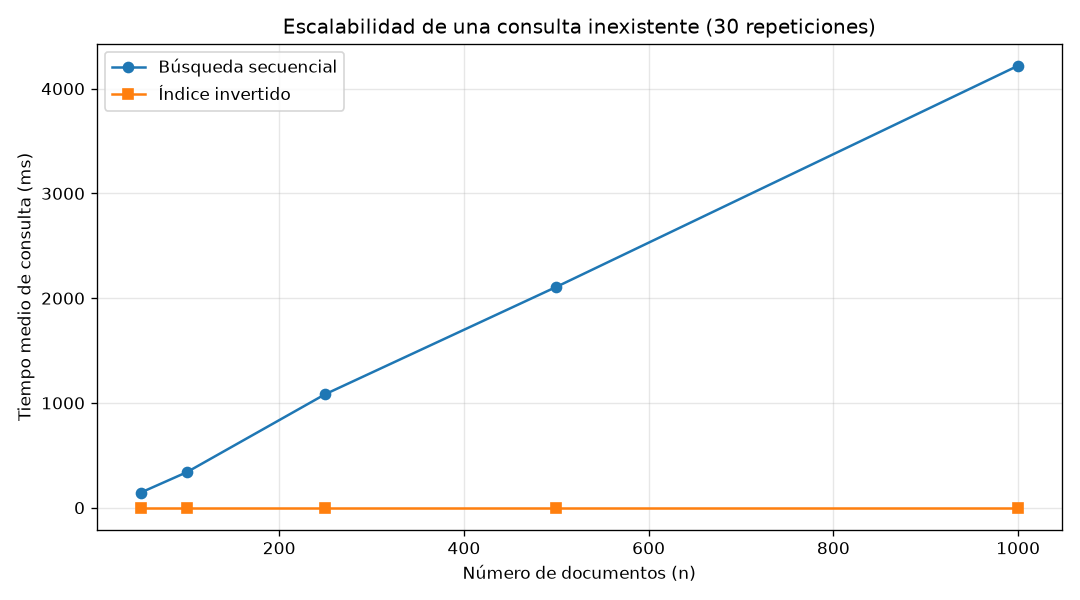

In [12]:
import matplotlib.pyplot as plt

TAMANOS = [50, 100, 250, 500, 1000]
CONSULTA_ESCALA = "zzzxqnotaword"
TERMINO_ESCALA = normalizar_termino(CONSULTA_ESCALA)
resultados_escala = []

for n in TAMANOS:
    ids_n = ids_grandes[:n]
    documentos_n = {}
    for libro_id in ids_n:
        documentos_n[libro_id] = tokens_grandes[libro_id]
    tokens_n = 0
    for libro_id in documentos_n:
        tokens_n += len(documentos_n[libro_id])
    indice_n = construir_indice_invertido(documentos_n)
    universo_n = frozenset(documentos_n)
    sec = busqueda_secuencial(TERMINO_ESCALA, documentos_n)
    inv = consulta_indice(
        "TERM", TERMINO_ESCALA, None, indice_n, universo_n
    )
    assert sec == inv
    fila = {
        "n": n,
        "consulta": CONSULTA_ESCALA,
        "tokens": tokens_n,
        "documentos_encontrados": len(sec),
        "secuencial_ms": tiempo_medio_ms(
            busqueda_secuencial, TERMINO_ESCALA, documentos_n
        ),
        "indice_ms": tiempo_medio_ms(
            consulta_indice, "TERM", TERMINO_ESCALA,
            None, indice_n, universo_n
        ),
    }
    resultados_escala.append(fila)

print(f"{'n':>5} {'Tokens':>12} {'Secuencial (ms)':>18} {'Indice (ms)':>15}")
for fila in resultados_escala:
    print(f"{fila['n']:>5} {fila['tokens']:>12,} "
          f"{fila['secuencial_ms']:>18.6f} {fila['indice_ms']:>15.6f}")

x = []
y_sec = []
y_inv = []
for fila in resultados_escala:
    x.append(fila["n"])
    y_sec.append(fila["secuencial_ms"])
    y_inv.append(fila["indice_ms"])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, y_sec, "o-", label="Búsqueda secuencial")
ax.plot(x, y_inv, "s-", label="Índice invertido")
ax.set_xlabel("Número de documentos (n)")
ax.set_ylabel("Tiempo medio de consulta (ms)")
ax.set_title("Escalabilidad de una consulta inexistente (30 repeticiones)")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


**9. Estimación de una función de tiempo**

Se ajustó "t(n)=an+b" por mínimos cuadrados a los cinco pares de tamaño y tiempo de cada método. La pendiente se obtuvo como la suma de productos de desviaciones dividida por la suma de cuadrados de las desviaciones del tamaño, donde el intercepto se calculó con las medias. El coeficiente "R²=1-SSE/SST" compara el error cuadrático del ajuste con la variación total respecto a la media. Estos parámetros describen las cinco mediciones observadas, pero no establecen por sí solos la complejidad.

Secuencial: t(n) = 4.287864376·n + -50.774592 ms; R² = 0.999423
Indice: t(n) = -0.000000417·n + 0.000638 ms; R² = 0.883709


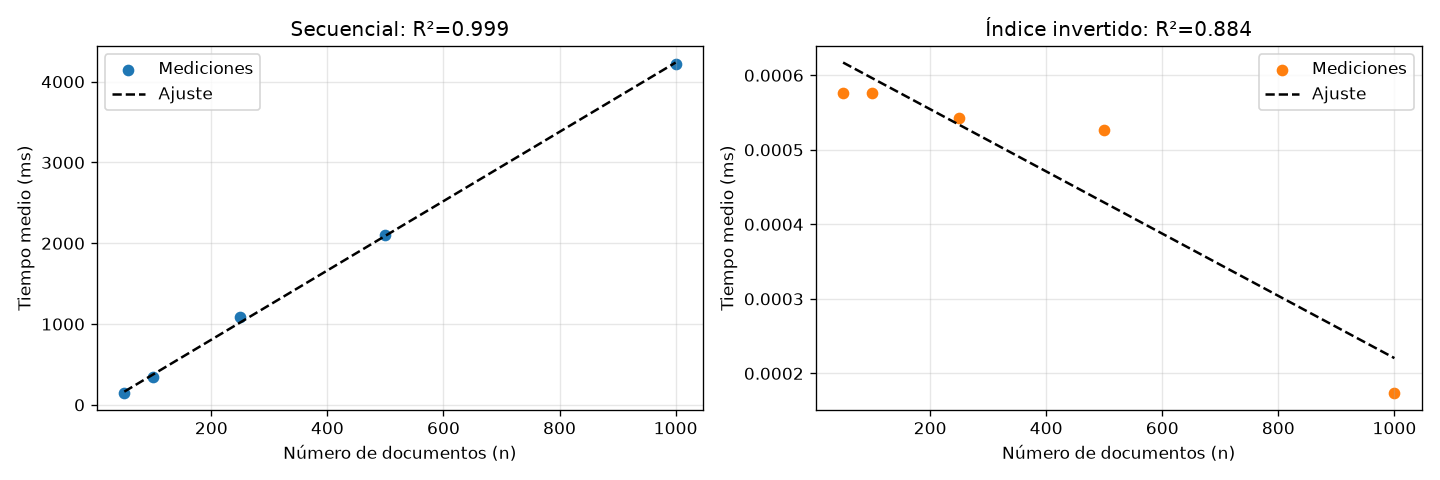

In [13]:
def ajuste_lineal_minimos_cuadrados(xs, ys):
    if len(xs) != len(ys) or len(xs) < 2:
        raise ValueError("Se necesitan al menos dos pares (n, tiempo)")

    cantidad = len(xs)
    suma_x = 0
    suma_y = 0
    for posicion in range(cantidad):
        suma_x += xs[posicion]
        suma_y += ys[posicion]
    media_x = suma_x / cantidad
    media_y = suma_y / cantidad

    sxx = 0
    sxy = 0
    for posicion in range(cantidad):
        diferencia_x = xs[posicion] - media_x
        diferencia_y = ys[posicion] - media_y
        sxx += diferencia_x ** 2
        sxy += diferencia_x * diferencia_y
    if sxx == 0:
        raise ValueError("Todos los tamaños del corpus son iguales")

    a = sxy / sxx
    b = media_y - a * media_x
    predicciones = []
    for valor_x in xs:
        predicciones.append(a * valor_x + b)

    sse = 0
    sst = 0
    for posicion in range(cantidad):
        diferencia_modelo = ys[posicion] - predicciones[posicion]
        diferencia_media = ys[posicion] - media_y
        sse += diferencia_modelo ** 2
        sst += diferencia_media ** 2

    if sst == 0:
        if sse == 0:
            r2 = 1.0
        else:
            r2 = float("nan")
    else:
        r2 = 1 - sse / sst
    return a, b, r2, predicciones


ajuste_sec = ajuste_lineal_minimos_cuadrados(x, y_sec)
ajuste_inv = ajuste_lineal_minimos_cuadrados(x, y_inv)

a_sec, b_sec, r2_sec, pred_sec = ajuste_sec
a_inv, b_inv, r2_inv, pred_inv = ajuste_inv
print(f"Secuencial: t(n) = {a_sec:.9f}·n + {b_sec:.6f} ms; R² = {r2_sec:.6f}")
print(f"Indice: t(n) = {a_inv:.9f}·n + {b_inv:.6f} ms; R² = {r2_inv:.6f}")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ax_sec = ejes[0]
ax_sec.scatter(x, y_sec, color="tab:blue", label="Mediciones")
ax_sec.plot(x, pred_sec, color="black", linestyle="--", label="Ajuste")
ax_sec.set_title(f"Secuencial: R²={r2_sec:.3f}")
ax_sec.set_xlabel("Número de documentos (n)")
ax_sec.set_ylabel("Tiempo medio (ms)")
ax_sec.grid(True, alpha=0.3)
ax_sec.legend()

ax_inv = ejes[1]
ax_inv.scatter(x, y_inv, color="tab:orange", label="Mediciones")
ax_inv.plot(x, pred_inv, color="black", linestyle="--", label="Ajuste")
ax_inv.set_title(f"Índice invertido: R²={r2_inv:.3f}")
ax_inv.set_xlabel("Número de documentos (n)")
ax_inv.set_ylabel("Tiempo medio (ms)")
ax_inv.grid(True, alpha=0.3)
ax_inv.legend()

fig.tight_layout()
plt.show()


Para la búsqueda secuencial se obtuvo "t(n)=4,287864376 n − 50,774592" ms, con "R²=0,999423". El intercepto negativo es una extrapolación del ajuste que no representa una duración negativa. Para el índice se obtuvo aproximadamente "t(n)=−0,000000417 n + 0,000638" ms, con "R²=0,883709". Eso indica que sus diferencias entre tamaños son fracciones de una milésima de milisegundo, donde la pequeña pendiente negativa no prueba que añadir libros acelere las consultas.

### Interpretaciones

En el archivo grande se encontraron 78.145 archivos TXT con identificadores válidos y distintos. Según las reglas usadas para reconocer sus nombres, no hubo archivos descartados ni versiones repetidas. Las búsquedas y las mediciones se hicieron sobre una muestra de 1.000 libros y sobre grupos más pequeños de esa muestra, por lo que no se consultaron los 78.145 libros a la vez. En el corpus pequeño de NLTK se procesaron 18 documentos y se obtuvieron 2.182.038 tokens y un vocabulario de 43.824 términos. Estos recuentos dependen de la normalización elegida, ya que lo que se hizo conserva las tildes, los números y los apóstrofos dentro de las palabras. En esos 18 documentos, "the" apareció en todos, "whale" en seis y "zzzxqnotaword" en ninguno.

Además, en las seis consultas comparadas sobre NLTK se recupero lo mismo ya que, la búsqueda secuencial y el índice invertido devolvieron los mismos identificadores. También coincidieron en las consultas realizadas sobre los grupos de 50, 250 y 1.000 libros del corpus grande. El orden en que se mostraron los identificadores no afectó la comparación, porque ambos métodos se comprobaron mediante conjuntos.

También se evidenció que cuando la palabra estaba ausente, la búsqueda secuencial tuvo que revisar todos los tokens de los documentos consultados. El índice, en cambio, pudo comprobar que la palabra no tenía una entrada con documentos asociados, sin recorrer otra vez los textos. En las mediciones del corpus pequeño, la consulta ausente tardó 103,779623 ms con búsqueda secuencial y 0,000297 ms con el índice. Sin embargo, es necesario aclarar que la construcción del índice se hizo antes de medir las consultas. Por ello, los tiempos tan pequeños del método indexado representan la búsqueda en un índice ya construido, no el costo de prepararlo y procesarlo. Crear y guardar ese índice requiere tiempo y memoria también.

Para la primera gráfica (de escalabilidad), se tuvo que al pasar de 50 a 1.000 libros, los tokens aumentaron de 2.382.611 a 72.546.330. El tiempo medio de la búsqueda secuencial pasó de 143,654520 ms a 4219,170663 ms, mostrando que como la palabra no existe, cada grupo más grande obliga a revisar más tokens como consecuencia Asimismo, los tiempos del índice permanecieron por debajo de 0,001 ms donde para 1.000 libros se registraron 0,000173 ms. En la gráfica compartida, su línea aparece casi pegada a cero porque los tiempos secuenciales son mucho mayores. El número de libros sirve como eje horizontal, pero el trabajo de la búsqueda secuencial depende más directamente del total de tokens ya que, dos grupos con igual cantidad de libros podrían tardar distinto si sus libros tuvieran longitudes diferentes.

Para la segunda gráfica, para la búsqueda secuencial se obtuvo:
$$
t(n)=4{,}287864376n-50{,}774592\ \text{ms},\qquad R^2=0{,}999423.
$$
La recta se acerca mucho a las mediciones dentro del intervalo probado. El valor negativo cuando \(n=0\) no es un tiempo real, si no que resultó de prolongar matemáticamente la recta fuera de los tamaños medidos.

Para el índice se obtuvo:
$$
t(n)=-0{,}000000417n+0{,}000638\ \text{ms},\qquad R^2=0{,}883709.
$$
Aquí la pendiente negativa no significa que añadir libros haga más rápida la búsqueda, si no que, al todos los tiempos del índice ser extremadamente pequeños, se tiene que las variaciones mínimas de la medición influyen mucho en la inclinación de la recta. Los valores de \(R^2\) también no demuestran por sí solos cómo se comportarán los métodos con cualquier cantidad de libros.

##### ¿Cómo se relaciona esto con los algoritmos?

Para una palabra ausente, la búsqueda secuencial compara la palabra con todos los tokens del grupo. Su trabajo crece con la suma de cada uno de los tokens, por lo que podemos llamar \(T\), de ahí que su costo es \(O(T)\). Si la palabra aparece en un documento, se deja de revisar ese documento tras encontrar la primera coincidencia.

El índice sin embargo recorre los tokens durante su construcción y guarda qué documentos contienen cada término. Por ello después de consultar una palabra ausente se requiere, en promedio, una búsqueda en el diccionario de costo \(O(1)\). Las consultas AND, OR y NOT necesitan además combinar conjuntos de documentos, por lo que no tienen exactamente el mismo trabajo que una consulta de un solo término.

##### ¿Qué recursos y límites tuvo el experimento?

Los textos seleccionados sumaron 426.174.939 bytes, mientras que el ZIP completo ocupó 11.322.987.679 bytes. Se leyeron los libros elegidos del TAR sin guardar una extracción completa de este por motivos de almacenamiento. Al cargar los tokens, la memoria residente de Python aumentó aproximadamente 3831,02 MiB, donde al mantener el índice de 1.000 documentos se registraron 669,4 MiB adicionales. 

También cada tiempo mostrado es una media de 30 ejecuciones, pero puede variar si se repite el experimento por el estado del equipo y de la memoria, que en este caso se realizó con 16gb de RAM pero si se tiene menos, puede generar problemas o inconvenientes en el sistema. La muestra se escogió por el orden de los libros en el archivo, no al azar, y tampoco se filtró por idioma. Por tanto, no se garantiza que todas las búsquedas produzcan el mismo resultado